# Milestone 4 — Best model, error analysis and fairness (Sessions 8–9)

**Course:** Computer Vision and Speech Recognition — EADA · **Student:** Kristof Papp

**Code (GitHub):** https://github.com/kristofpapp330/milk10k-cv-course/blob/main/notebooks/m4_best_model.ipynb

| what | file |
|---|---|
| this notebook (Google Colab, T4 GPU) | `notebooks/m4_best_model.ipynb` |
| models / training | `milk10k_pipeline/deep.py` |
| metrics, fairness | `milk10k_pipeline/evaluation.py` |
| rough lesion mask (Session 8: blur → Otsu → region) | `milk10k_pipeline/features.py` |
| results | `outputs/deep/` (scoreboard, `m4_test_predictions.csv`, `best_model.json`); checkpoint `model_m4.pt` |

**Plan (brief, Milestone 4).**
1. Add a **ViT-B/16** next to the ResNet-18 of Milestone 3, on the same split, with the same target and metric:
   first the Session 9 fair comparison (both **frozen + the same linear head**), then both **partly fine-tuned**.
2. Choose the best model by **validation macro-F1**; report **test once**.
3. **Error analysis:** confusion matrix, per-diagnosis results, 10 misclassified images with the Session 8 mask.
4. **Fairness check:** macro-F1 per `skin_tone_class` and per `sex`.
5. **Scoreboard:** every model from M2 to M4, same test split, same metric.

Run `m3_deep_models.ipynb` first: this notebook reads its saved predictions from Drive.

## 0. Setup (Google Colab)
**Before running:** *Runtime → Change runtime type → T4 GPU*. Then *Runtime → Run all*.
Google asks once for permission to use your Drive: everything that must survive the session
(image cache, predictions, checkpoints) is saved in `MyDrive/milk10k_project/`.

In [1]:
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
QUICK = os.environ.get("MILK10K_QUICK") == "1"        # offline test mode only (tiny subset, 1 epoch)
REPO_URL = "https://github.com/kristofpapp330/milk10k-cv-course.git"
DATA_URL = "https://isic-archive.s3.amazonaws.com/dois/10.34970-648456/milk10k.zip"

def run(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/milk10k_project")
    repo = Path("/content/milk10k-cv-course")
    if repo.exists():
        run(f"git -C {repo} pull --ff-only")
    else:
        run(f"git clone --depth 1 {REPO_URL} {repo}")
    os.chdir(repo)
    data_root = Path("/content/milk10k")
    if not list(data_root.rglob("metadata.csv")):
        zip_path = WORK / "milk10k.zip"                   # option 1: you uploaded the zip to Drive
        if not zip_path.exists():                         # option 2: download it (about 1-2 minutes)
            zip_path = Path("/content/milk10k.zip")
            run(f"wget -q -O {zip_path} {DATA_URL}")
        print("unzipping ...")
        zipfile.ZipFile(zip_path).extractall(data_root)
    os.environ["MILK10K_DIR"] = str(next(data_root.rglob("metadata.csv")).parent)
else:                                                     # local run (testing)
    repo = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(repo)
    WORK = Path(os.environ.get("MILK10K_WORK", repo / "outputs" / "deep_work"))

sys.path.insert(0, str(Path.cwd()))
WORK.mkdir(parents=True, exist_ok=True)
DEEP = WORK / "outputs_deep"                              # small results -> later copied to outputs/deep in the repo
PRED = DEEP / "predictions"
CKPT = WORK / "checkpoints"                               # model weights
FIG = DEEP / "figures"
for d in (DEEP, PRED, CKPT, FIG):
    d.mkdir(parents=True, exist_ok=True)

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from milk10k_pipeline import config, deep, evaluation as ev, mlp
from milk10k_pipeline.data_io import find_images

device = deep.get_device()
NUM_WORKERS = 2 if IN_COLAB else 0
print("device:", device, "| GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "none")
print("data:", config.DATA_DIR, "| results:", WORK)
if IN_COLAB and device.type != "cuda":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then run again.")

Mounted at /content/drive
$ git clone --depth 1 https://github.com/kristofpapp330/milk10k-cv-course.git /content/milk10k-cv-course
$ wget -q -O /content/milk10k.zip https://isic-archive.s3.amazonaws.com/dois/10.34970-648456/milk10k.zip
unzipping ...
device: cuda | GPU: Tesla T4
data: /content/milk10k | results: /content/drive/MyDrive/milk10k_project


### The data: Milestone 1 split (by lesion), one dermoscopic image per lesion

In [2]:
splits = {}
for name in ["train", "val", "test"]:
    df = pd.read_csv(config.SPLITS_DIR / f"{name}.csv")
    df = df[df["view"].isin(config.VIEWS)].reset_index(drop=True)
    df["y3"] = df["diagnosis_1"].map({c: i for i, c in enumerate(deep.CLASSES3)})
    df["y11"] = df["dx"].map({c: i for i, c in enumerate(deep.CLASSES11)})
    if QUICK:
        df = pd.concat([g.head(40) for _, g in df.groupby("y3")]).reset_index(drop=True)
    splits[name] = df
train, val, test = splits["train"], splits["val"], splits["test"]
assert not (set(train.lesion_id) & set(val.lesion_id)) and not (set(train.lesion_id) & set(test.lesion_id)) \
    and not (set(val.lesion_id) & set(test.lesion_id)), "lesion leakage between splits!"
print({k: len(v) for k, v in splits.items()}, "lesions")

image_paths = find_images()
all_ids = pd.concat([train, val, test])["isic_id"].tolist()
cache = deep.build_cache(all_ids, image_paths, cache_path=WORK / ("cache224_quick.npz" if QUICK else "cache224.npz"))
n_tr, n_va = len(train), len(val)
IMG = {"train": cache[:n_tr], "val": cache[n_tr:n_tr + n_va], "test": cache[n_tr + n_va:]}
Y3 = {s: splits[s]["y3"].to_numpy() for s in splits}
Y11 = {s: splits[s]["y11"].to_numpy() for s in splits}
EPOCHS = 1 if QUICK else None

{'train': 3143, 'val': 1048, 'test': 1049} lesions
loaded image cache (5240 images) from /content/drive/MyDrive/milk10k_project/cache224.npz


---
## Common helpers (identical in the M3 and M4 notebooks)
Every deep model is scored like every earlier model: **3-class macro-F1 on the same validation lesions**.
Test predictions are saved now, but they are only looked at in the Milestone 4 scoreboard, after the
best model has been chosen on validation.

In [3]:
REGISTRY = DEEP / "models.json"      # every deep model: its file names and validation numbers

def file_key(name):
    return name.replace("/", "-").replace(" ", "_").replace("+", "and")

def save_predictions(name, proba_val, proba_test, info, Y=None):
    Y = Y3 if Y is None else Y
    key = file_key(name)
    np.savez(PRED / f"{key}.npz", val=proba_val, test=proba_test)
    f1 = ev.macro_f1(Y["val"], proba_val.argmax(1), proba_val.shape[1])
    registry = json.loads(REGISTRY.read_text()) if REGISTRY.exists() else {}
    registry[name] = {"predictions": f"{key}.npz", "val_macro_f1": round(f1, 4), **info}
    REGISTRY.write_text(json.dumps(registry, indent=2))
    print(f"{name}: validation macro-F1 = {f1:.3f}")

def plot_history(hist, title, name):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(hist.epoch, hist.train_loss, "--", label="train"); ax[0].plot(hist.epoch, hist.val_loss, label="validation")
    ax[0].set_title("class-weighted cross-entropy"); ax[0].legend()
    ax[1].plot(hist.epoch, hist.val_macro_f1, color="#eb6834"); ax[1].set_title("validation macro-F1")
    ax[1].axvline(hist.val_macro_f1.idxmax() + 1, ls=":", color="gray")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=0.3)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=120); plt.show()

def finetune(name, Y=None, classes=None, tag=""):
    """Train one recipe of deep.RECIPES end to end and save its predictions + checkpoint.
    Y / classes: the labels (default: the 3 diagnosis_1 classes); tag is added to the saved name."""
    Y, classes = (Y3, deep.CLASSES3) if Y is None else (Y, classes)
    k = len(classes)
    r = deep.RECIPES[name]
    out_name = name + tag
    model = deep.build_model(r["arch"], n_classes=k, pretrained=r["pretrained"])
    deep.freeze(model, r["trainable"])
    print(f"{name}: {deep.n_trainable(model):,} trainable of {deep.n_total(model):,} parameters")
    tl = deep.make_loader(IMG["train"], Y["train"], train=True, num_workers=NUM_WORKERS)
    vl = deep.make_loader(IMG["val"], Y["val"], train=False, num_workers=NUM_WORKERS)
    te = deep.make_loader(IMG["test"], Y["test"], train=False, num_workers=NUM_WORKERS)
    start = time.time()
    model, hist, best_epoch = deep.train_model(model, r, tl, vl, Y["train"], Y["val"], k, device, epochs=EPOCHS)
    minutes = (time.time() - start) / 60
    hist.to_csv(DEEP / f"history_{file_key(out_name)}.csv", index=False)
    plot_history(hist, f"{out_name} ({minutes:.1f} min)", file_key(out_name))
    ckpt = deep.save_checkpoint(model, CKPT / f"{file_key(out_name)}.pt", r["arch"],
                                classes, r["trainable"], r["pretrained"])
    save_predictions(out_name, deep.predict_proba(model, vl, device), deep.predict_proba(model, te, device),
                     {"kind": "finetune", "arch": r["arch"], "trainable params": deep.n_trainable(model),
                      "best epoch": best_epoch, "minutes": round(minutes, 1),
                      "sec per epoch": round(hist.seconds.mean(), 1), "checkpoint": ckpt.name}, Y=Y)
    return model, hist

def frozen_head(name, arch, seeds=(0, 1, 2), Y=None, classes=None, tag=""):
    """Session 7 strategy 1 / Session 9 fair comparison: frozen backbone -> embeddings once -> linear head
    trained with the Session 6 code (class weights, Adam 1e-3, batch 64, early stopping), 3 seeds."""
    emb_file = WORK / f"embeddings_{arch}{'_quick' if QUICK else ''}.npz"
    if emb_file.exists():
        E = dict(np.load(emb_file))
    else:
        start = time.time()
        E = {s: deep.backbone_embeddings(arch, IMG[s], device, num_workers=NUM_WORKERS) for s in IMG}
        np.savez(emb_file, **E)
        print(f"embeddings computed in {time.time() - start:.0f}s: {E['train'].shape[1]} numbers per lesion")
    Y, classes = (Y3, deep.CLASSES3) if Y is None else (Y, classes)
    k, out_name = len(classes), name + tag
    runs = []
    for seed in seeds:
        head, hist, best_epoch = mlp.train_mlp(E["train"].astype(np.float32), Y["train"], E["val"].astype(np.float32),
                                               Y["val"], k, hidden=(), seed=seed, epochs=EPOCHS or 50)
        runs.append((hist["val_macro_f1"].max(), seed, head, hist))
    vals = [r[0] for r in runs]
    best_f1, best_seed, head, hist = max(runs, key=lambda r: r[0])
    full = deep.model_from_frozen_head(arch, head[0], k)
    head_prefix = ["fc"] if arch == "resnet18" else ["heads"]
    ckpt = deep.save_checkpoint(full, CKPT / f"{file_key(out_name)}.pt", arch, classes, head_prefix)
    p_val = mlp.predict_proba(head, E["val"].astype(np.float32))
    p_test = mlp.predict_proba(head, E["test"].astype(np.float32))
    save_predictions(out_name, p_val, p_test, {"kind": "frozen", "arch": arch, "trainable params": mlp.n_parameters(head),
                                           "seed val macro-F1 (3 seeds)": [round(v, 3) for v in vals],
                                           "chosen seed": best_seed, "best epoch": int(hist["val_macro_f1"].idxmax()) + 1,
                                           "checkpoint": ckpt.name}, Y=Y)
    plot_history(hist, f"{out_name} (linear head on frozen embeddings, seed {best_seed})", file_key(out_name))
    return hist

---
## 1. ViT-B/16 vs ResNet-18, the fair way: both frozen + the same linear head (Session 9)
Only the backbone changes: ResNet-18 gives 512 numbers per lesion, ViT-B/16 gives 768 (the class token).
Same head (one linear layer), same training (Session 6 code, 3 seeds), same split, same metric.

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 126MB/s]


embeddings computed in 26s: 768 numbers per lesion
ViT-B/16 frozen + head: validation macro-F1 = 0.618


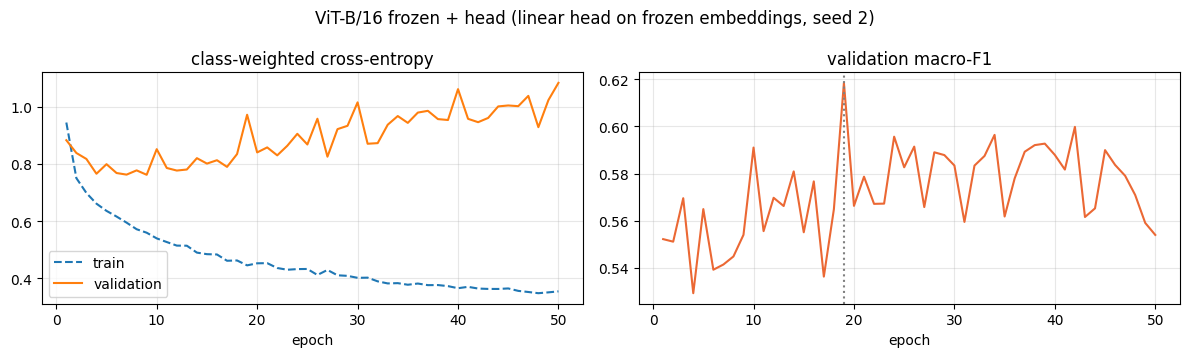

,epoch,train_loss,val_loss,val_macro_f1
0,1,0.945766,0.883855,0.552267
1,2,0.751123,0.839143,0.551190
2,3,0.699041,0.818192,0.569590
3,4,0.661671,0.766470,0.529358
4,5,0.636491,0.799939,0.564981
5,6,0.616664,0.769008,0.539311
6,7,0.595265,0.763385,0.541508
7,8,0.572175,0.778292,0.544929
8,9,0.560043,0.762822,0.554093
9,10,0.540161,0.852490,0.591055


In [4]:
frozen_head("ViT-B/16 frozen + head", "vit_b_16")

## 2. ViT-B/16, fine-tune the last 2 encoder blocks + head
The GPU makes it possible to adapt part of the ViT too (on a laptop CPU this would take hours, Session 9).
Same idea as ResNet strategy 2: the last blocks + the new head are trained, everything before stays ImageNet.

ViT-B/16 fine-tune last 2 blocks: 14,179,587 trainable of 85,800,963 parameters
  epoch  1: train loss 0.926 | val loss 0.819 | val macro-F1 0.530 | 22s
  epoch  2: train loss 0.692 | val loss 0.779 | val macro-F1 0.521 | 21s
  epoch  3: train loss 0.626 | val loss 0.768 | val macro-F1 0.523 | 22s
  epoch  4: train loss 0.532 | val loss 0.999 | val macro-F1 0.532 | 22s
  epoch  5: train loss 0.565 | val loss 0.808 | val macro-F1 0.563 | 23s
  epoch  6: train loss 0.460 | val loss 1.123 | val macro-F1 0.611 | 22s
  epoch  7: train loss 0.489 | val loss 1.053 | val macro-F1 0.616 | 23s
  epoch  8: train loss 0.456 | val loss 1.092 | val macro-F1 0.585 | 22s
  epoch  9: train loss 0.370 | val loss 1.192 | val macro-F1 0.616 | 23s
  epoch 10: train loss 0.408 | val loss 1.134 | val macro-F1 0.609 | 22s


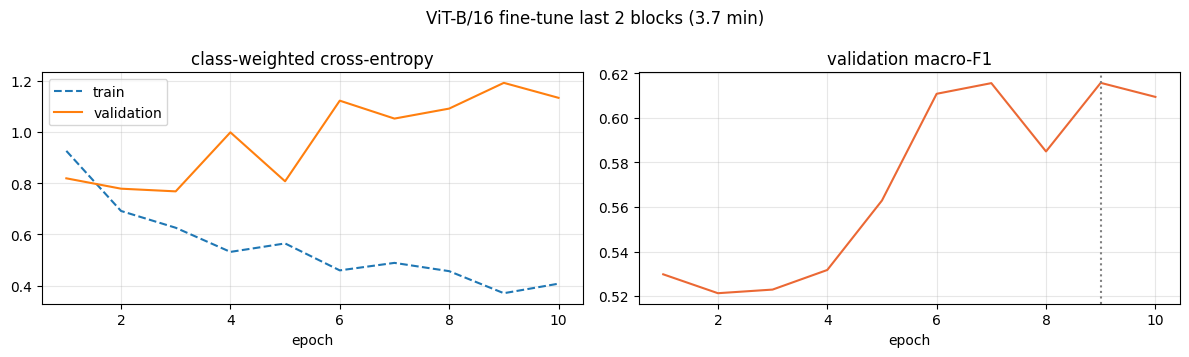

ViT-B/16 fine-tune last 2 blocks: validation macro-F1 = 0.616


In [5]:
vit, vit_hist = finetune("ViT-B/16 fine-tune last 2 blocks")

---
## 3. Choosing the best model — on VALIDATION only

In [6]:
registry = json.loads(REGISTRY.read_text())
DEEP_NAMES = ["CNN from scratch", "ResNet-18 frozen + head", "ResNet-18 fine-tune layer4",
              "ResNet-18 fine-tune layer3+4", "ViT-B/16 frozen + head", "ViT-B/16 fine-tune last 2 blocks"]
missing = [n for n in DEEP_NAMES if n not in registry]
assert not missing, f"run the M3 notebook first, missing: {missing}"
P = {n: dict(np.load(PRED / registry[n]["predictions"])) for n in DEEP_NAMES}

val_table = pd.DataFrame([{"model": n, "val macro-F1": ev.macro_f1(Y3["val"], P[n]["val"].argmax(1), 3),
                           "trainable params": registry[n]["trainable params"], "kind": registry[n]["kind"]}
                          for n in DEEP_NAMES]).sort_values("val macro-F1", ascending=False)
BEST = val_table.iloc[0]["model"]
print("BEST on validation:", BEST)
val_table.round(3)

BEST on validation: ResNet-18 fine-tune layer3+4


,model,val macro-F1,trainable params,kind
3,ResNet-18 fine-tune layer3+4,0.633,10494979,finetune
2,ResNet-18 fine-tune layer4,0.621,8395267,finetune
4,ViT-B/16 frozen + head,0.618,2307,frozen
5,ViT-B/16 fine-tune last 2 blocks,0.616,14179587,finetune
1,ResNet-18 frozen + head,0.603,1539,frozen
0,CNN from scratch,0.525,390147,finetune


## 4. The scoreboard: every model M2 → M4, same split, same target (3 classes), same metric
Test macro-F1 is shown for every model (as the brief's template asks), but **only the validation column
was used to choose**. Deep models: one training run each (frozen + head: the best of 3 seeds on validation).

In [7]:
def maj(split):
    m = int(pd.Series(Y3["train"]).mode()[0])
    return ev.macro_f1(Y3[split], np.full(len(Y3[split]), m), 3)

rows = [{"milestone": "—", "model": "majority class (floor)", "val macro-F1": maj("val"), "test macro-F1": maj("test")}]
if not QUICK:
    base = json.loads((config.OUTPUT_DIR / "baseline" / "test_results.json").read_text())["three_class"]
    rows.append({"milestone": "M2 (S5)", "model": "SVM (RBF) on 45 handcrafted features",
                 "val macro-F1": base["validation"]["macro_f1"], "test macro-F1": base["test"]["macro_f1"]})
    s6 = json.loads((config.OUTPUT_DIR / "mlp" / "summary.json").read_text())
    for key, label in [("45 features | 3-class", "MLP on 45 handcrafted features"),
                       ("raw pixels 32x32x3 | 3-class", "MLP on raw pixels 32×32×3")]:
        rows.append({"milestone": "M3 (S6)", "model": label + " (mean of 3 seeds)",
                     "val macro-F1": s6[key]["val mean"], "test macro-F1": s6[key]["test mean"]})
for n in DEEP_NAMES:
    lo, hi = ev.bootstrap_macro_f1(Y3["test"], P[n]["test"].argmax(1), 3, n_boot=1000)
    rows.append({"milestone": "M4 (S9)" if "ViT" in n else "M3 (S7)", "model": n,
                 "val macro-F1": ev.macro_f1(Y3["val"], P[n]["val"].argmax(1), 3),
                 "test macro-F1": ev.macro_f1(Y3["test"], P[n]["test"].argmax(1), 3),
                 "test 95% CI": f"[{lo:.3f}, {hi:.3f}]"})
scoreboard = pd.DataFrame(rows)
scoreboard["chosen"] = np.where(scoreboard["model"] == BEST, "◀ best on validation", "")
scoreboard.to_csv(DEEP / "scoreboard_3class.csv", index=False)
scoreboard.round(3)

,milestone,model,val macro-F1,test macro-F1,test 95% CI,chosen
0,—,majority class (floor),0.272,0.273,NaN,
1,M2 (S5),SVM (RBF) on 45 handcrafted features,0.567,0.518,NaN,
2,M3 (S6),MLP on 45 handcrafted features (mean of 3 seeds),0.559,0.549,NaN,
3,M3 (S6),MLP on raw pixels 32×32×3 (mean of 3 seeds),0.540,0.525,NaN,
4,M3 (S7),CNN from scratch,0.525,0.470,"[0.431, 0.507]",
5,M3 (S7),ResNet-18 frozen + head,0.603,0.571,"[0.517, 0.626]",
6,M3 (S7),ResNet-18 fine-tune layer4,0.621,0.622,"[0.559, 0.681]",
7,M3 (S7),ResNet-18 fine-tune layer3+4,0.633,0.578,"[0.523, 0.634]",◀ best on validation
8,M4 (S9),ViT-B/16 frozen + head,0.618,0.583,"[0.532, 0.633]",
9,M4 (S9),ViT-B/16 fine-tune last 2 blocks,0.616,0.597,"[0.550, 0.646]",


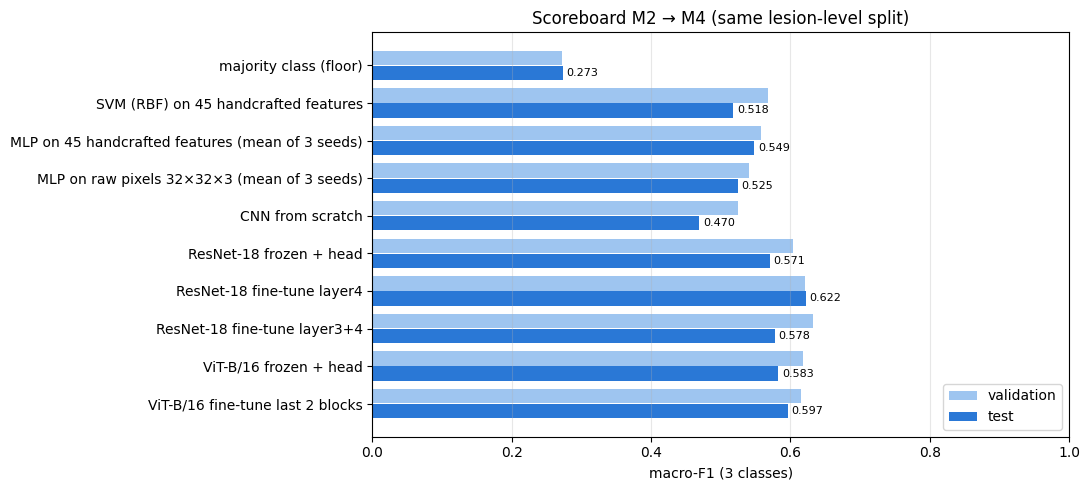

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
ypos = np.arange(len(scoreboard))[::-1]
ax.barh(ypos + 0.2, scoreboard["val macro-F1"], 0.38, color="#9ec5f0", label="validation")
ax.barh(ypos - 0.2, scoreboard["test macro-F1"], 0.38, color="#2a78d6", label="test")
for y_, v in zip(ypos - 0.2, scoreboard["test macro-F1"]):
    ax.text(v + 0.005, y_, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(ypos, scoreboard["model"]); ax.set_xlabel("macro-F1 (3 classes)"); ax.set_xlim(0, 1)
ax.set_title("Scoreboard M2 → M4 (same lesion-level split)"); ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "m4_scoreboard.png", dpi=120); plt.show()

**Observations scoreboard**

- **Deep beats handcrafted.** Every pretrained model (validation 0.60–0.63, test 0.57–0.62) is clearly above
  the best classical model (SVM: 0.567 / 0.518) and the Session 6 MLPs. The CNN from scratch (0.525 / 0.470) is
  the exception: without pretraining, 3,143 images are not enough.
- **ViT-B/16 vs ResNet-18 (the brief's question):**
  - In the fair comparison (both frozen, same linear head), ViT is slightly better: validation 0.618 vs 0.603,
    test 0.583 vs 0.571.
  - Fine-tuned, ResNet is ahead on validation (0.633 vs 0.616) and the ViT on test (0.597 vs 0.578).
  - All 95 % intervals overlap widely, so **there is no clear winner**. This matches Session 9: a ViT has fewer
    built-in assumptions (no locality) and needs more data to show its advantage, and 3,143 lesions is a small
    dataset.
  - ResNet-18 is far cheaper: 11 M vs 86 M parameters, 17 vs 22 s per epoch, and a 42 MB vs 57 MB checkpoint.
- **The chosen model** (rule fixed in advance: best validation macro-F1) is **ResNet-18 fine-tune layer3+4**:
  validation 0.633, **test 0.578 [0.523, 0.634]**.
  - On test, its sibling with only layer4 trainable scored higher (0.622), but its interval [0.559, 0.681]
    overlaps.
  - The validation gap between them (0.012) is noise from a single training run.
  - We do **not** switch models after looking at test: that would turn the test split into a second
    validation split and make the reported number optimistic.

---
## 5. The best model on TEST (evaluated once)

ResNet-18 fine-tune layer3+4 | test macro-F1: 0.578


,n,recall,F1
Benign,298,0.725,0.600
Malignant,728,0.706,0.778
Indeterminate,23,0.435,0.357


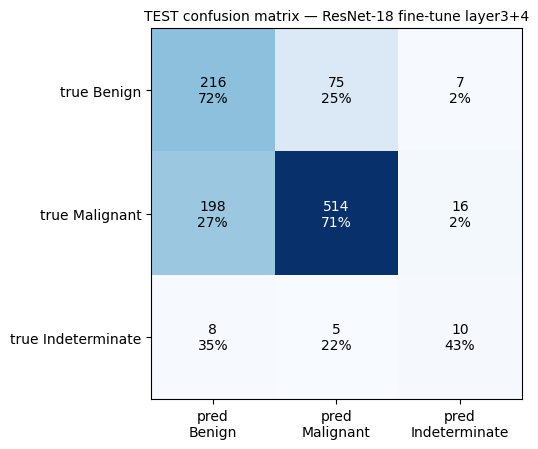

In [9]:
p_test = P[BEST]["test"]
pred = p_test.argmax(1)
print(BEST, "| test macro-F1:", round(ev.macro_f1(Y3["test"], pred, 3), 3))
display(ev.per_class_table(Y3["test"], pred, deep.CLASSES3).round(3))

cm = ev.confusion_df(Y3["test"], pred, deep.CLASSES3)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(cm.values, cmap="Blues")
for i in range(3):
    for j in range(3):
        v = cm.values[i, j]
        ax.text(j, i, f"{v}\n{v / max(cm.values[i].sum(), 1):.0%}", ha="center", va="center",
                color="white" if v > cm.values.max() / 2 else "black", fontsize=10)
ax.set_xticks(range(3), [f"pred\n{c}" for c in deep.CLASSES3]); ax.set_yticks(range(3), [f"true {c}" for c in deep.CLASSES3])
ax.set_title(f"TEST confusion matrix — {BEST}", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "m4_confusion.png", dpi=120); plt.show()

**Observation.** On test the chosen model finds
- 72 % of benign lesions,
- 71 % of malignant lesions,
- 10 of the 23 Indeterminate lesions (43 %).

The most important error: **198 of 728 malignant lesions (27 %) are called Benign.**

### Clinical view and the melanoma question from Milestone 2
Malignant + Indeterminate = "needs clinical action". In Milestone 2 the SVM caught only **34 % of melanomas**.
Does the deep model fix that? (Share of test lesions of each diagnosis that end up on the right side:
benign diagnoses predicted Benign, malignant / AKIEC predicted Malignant or Indeterminate.)

In [10]:
true_bin, pred_bin = (Y3["test"] != 0).astype(int), (pred != 0).astype(int)
print(f"sensitivity (action needed, caught): {(pred_bin[true_bin == 1] == 1).mean():.3f} | "
      f"specificity (benign left alone): {(pred_bin[true_bin == 0] == 0).mean():.3f}")
per_dx = pd.DataFrame({"dx": test["dx"], "correct side": true_bin == pred_bin}).groupby("dx")["correct side"] \
    .agg(n="size", deep="mean")
if not QUICK:
    m2 = pd.read_csv(config.OUTPUT_DIR / "baseline" / "test_per_diagnosis.csv", index_col=0)
    per_dx["M2 SVM (binary)"] = m2["share correct"]
per_dx.sort_values("deep").round(3)

sensitivity (action needed, caught): 0.726 | specificity (benign left alone): 0.725


,n,deep,M2 SVM (binary)
dx,,,
MAL_OTH,2,0.000,0.500
INF,10,0.300,0.500
MEL,90,0.378,0.344
BKL,109,0.606,0.248
AKIEC,61,0.607,0.918
SCCKA,94,0.691,0.894
VASC,10,0.700,0.700
BEN_OTH,9,0.778,0.444
BCC,504,0.812,0.917


**Observation — did the deep model fix the melanoma problem of Milestone 2? Only partly.**
- **Balance:** sensitivity 0.726 and specificity 0.725, a much more balanced model than the SVM (0.844 / 0.597).
- **Big gains on benign lesions that look suspicious:**
  - benign keratosis (BKL): 61 % correct, against 25 % for the SVM
  - dermatofibroma (DF): 82 % against 36 %
- **Melanoma is still the weak spot: only 38 % caught** (SVM: 34 %). Pigmented melanomas still look like nevi to
  the model, and pink, poorly pigmented melanomas look benign too.
- The price of the better specificity: fewer BCC (81 %), AKIEC (61 %) and SCCKA (69 %) are caught than with the SVM.

For a screening tool this is not acceptable yet. It would need a lower decision threshold for malignancy and,
above all, a much better melanoma recall.

---
## 6. Error analysis: what do the misclassified lesions have in common?
10 misclassified test lesions (the most confident mistakes first), with the **Session 8 classical mask**
(Gaussian blur → Otsu threshold → central dark region, `features.lesion_mask`) drawn in yellow.

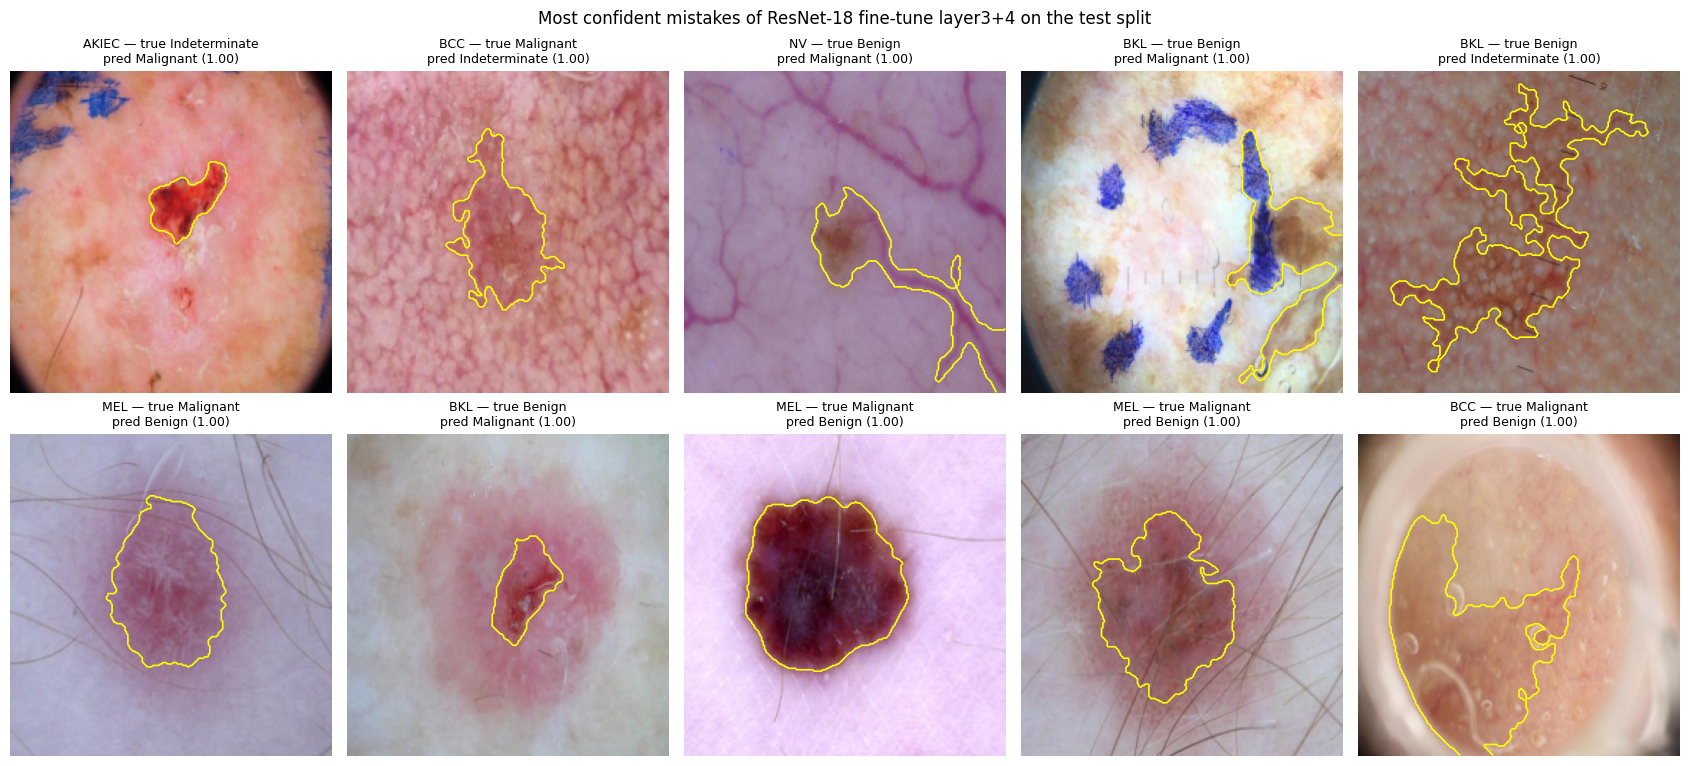

In [11]:
from milk10k_pipeline import features
wrong = np.where(pred != Y3["test"])[0]
order = wrong[np.argsort(-p_test[wrong].max(1))][:10]
fig, axes = plt.subplots(2, 5, figsize=(17, 8))
for ax, i in zip(axes.flat, order):
    img = IMG["test"][i]
    ax.imshow(img)
    mask = features.lesion_mask(features.to_gray(img.astype(float)))
    if mask is not None:
        ax.contour(mask, levels=[0.5], colors="yellow", linewidths=1.2)
    ax.set_title(f"{test.dx[i]} — true {deep.CLASSES3[Y3['test'][i]]}\npred {deep.CLASSES3[pred[i]]} "
                 f"({p_test[i].max():.2f}){'' if mask is not None else ' · no mask'}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Most confident mistakes of {BEST} on the test split"); plt.tight_layout()
plt.savefig(FIG / "m4_errors.png", dpi=110); plt.show()

### Do errors happen more where the lesion is hard to outline? (masks used to explain errors)
The Milestone 2 feature table already contains, for every image, whether the Otsu mask found a lesion
and how much darker the lesion is than the skin (`contrast`). Error rate of the best model by group:

In [12]:
if not QUICK:
    feats = pd.read_csv(config.OUTPUT_DIR / "baseline" / "features_dermoscopic.csv", index_col="isic_id")
    f_test = feats.loc[test.isic_id]
    contrast = f_test[["contrast_R", "contrast_G", "contrast_B"]].mean(axis=1).to_numpy()
    groups = pd.DataFrame({
        "mask": np.where(np.isnan(contrast), "no mask found (pale / faint lesion)", "mask found"),
        "contrast": pd.qcut(pd.Series(contrast), 3, labels=["low contrast", "medium", "high contrast"]).astype(str)
                      .where(~np.isnan(contrast), "no mask"),
        "error": pred != Y3["test"]})
    display(groups.groupby("mask")["error"].agg(n="size", error_rate="mean").round(3))
    display(groups.groupby("contrast")["error"].agg(n="size", error_rate="mean").round(3))

,n,error_rate
mask,,
mask found,910,0.307
no mask found (pale / faint lesion),139,0.216


,n,error_rate
contrast,,
high contrast,304,0.303
low contrast,303,0.317
medium,303,0.300
no mask,139,0.216


**Observations error analysis.** What the 10 most confident mistakes have in common:

1. **All are made with confidence ≈ 1.00.** The model is overconfident, which matches the rising validation loss
   seen in M3. Its probabilities cannot be read as "how sure it should be" without calibration.
2. **Acquisition artefacts:**
   - blue surgical-pen marks (2 of 10)
   - the dark round frame of the dermoscope
   - gel bubbles
   - hairs over the lesion

   The model may partly learn *how* a lesion was photographed instead of *what* it is (Session 8: shortcut
   learning).
3. **Melanomas that do not look like the textbook:** pink or hypopigmented melanomas and a regular,
   evenly dark one are called Benign.
4. **Scaly or red benign keratoses** are called Malignant. They look like the BCC/SCC majority.

**The masks.** The classical Session 8 mask (blur → Otsu → central region) often fails on exactly these images:
it follows blood vessels, pen marks or the dermoscope frame instead of the lesion. Classical segmentation cannot
be trusted on hard images, so a learned segmentation (U-Net) would be the next step before using
border/asymmetry features. Quantitatively:
- Errors are **not** concentrated on low-contrast lesions: about 30 % error in every contrast tercile.
- Lesions where no mask was found have *fewer* errors (22 %). These are mostly pale BCCs, the largest class,
  which the model handles well.

---
## 7. Fairness check: macro-F1 per skin tone and per sex (test split)
`skin_tone_class` and `sex` come from `metadata.csv`. They were never inputs of the model; here they are used
only to check whether the model works equally well for different groups. Small groups are flagged.

In [13]:
meta = pd.read_csv(config.METADATA_CSV)
info = meta.set_index("isic_id").reindex(test.isic_id)
for col in ["skin_tone_class", "sex"]:
    if col not in info:
        print(f"{col} not in metadata.csv"); continue
    rep = ev.group_report(Y3["test"], pred, info[col].to_numpy(), min_n=50)
    print(f"\nby {col}:"); display(rep.round(3))
    rep.to_csv(DEEP / f"m4_fairness_{col}.csv", index=False)

skin_tone_class not in metadata.csv

by sex:


,group,n lesions,classes present,macro-F1,95% CI,accuracy,note
0,female,414,3,0.649,"[0.51, 0.75]",0.729,
1,male,635,3,0.540,"[0.47, 0.61]",0.690,


**Observations fairness.**
- **Sex:**
  - Macro-F1 is 0.649 [0.51, 0.75] for women (414 lesions) and 0.540 [0.47, 0.61] for men (635).
  - Accuracy is 0.729 vs 0.690.
  - The intervals overlap, and macro-F1 inside a group depends heavily on the few Indeterminate lesions it
    contains, so **this is not evidence of a real difference**. It is a difference to monitor on more data.
- **Skin tone:** the `metadata.csv` of the MILK10k download has no skin-tone column. The skin tone class is in the
  challenge's training metadata, so this check is done with `run_fairness_skin_tone.py` on the saved test
  predictions (`outputs/deep/m4_test_predictions.csv`). The results are in
  `outputs/deep/m4_fairness_skin_tone_class.csv` and in the final report.

---
## 8. Save the Milestone 4 results
`model_m4.pt` (the chosen 3-class model) and its predictions on the test split.

In [14]:
import shutil
shutil.copy(CKPT / registry[BEST]["checkpoint"], DEEP / "model_m4.pt")
out = test[["isic_id", "lesion_id", "dx", "diagnosis_1"]].copy()
out["pred"] = [deep.CLASSES3[i] for i in pred]
for k, c in enumerate(deep.CLASSES3):
    out[f"p_{c}"] = p_test[:, k].round(4)
out.to_csv(DEEP / "m4_test_predictions.csv", index=False)
best_info = {"name": BEST, **registry[BEST]}
if BEST in deep.RECIPES:
    best_info["recipe"] = deep.RECIPES[BEST]
(DEEP / "best_model.json").write_text(json.dumps(best_info, indent=2))
print("saved model_m4.pt, m4_test_predictions.csv, best_model.json in", DEEP)

saved model_m4.pt, m4_test_predictions.csv, best_model.json in /content/drive/MyDrive/milk10k_project/outputs_deep
